# Predictia pierderii clientilor – V2

**Feature engineering, optimizarea hiperparametrilor si analiza greselilor**

Folosim aceiasi trei algoritmi ca in V1, dar adaugam **trei caracteristici noi**. Comparam rezultatele, analizam greselile si pastram **setul de test** pentru etapa finala.

### 1. Importam bibliotecile si incarcam datele
Importam bibliotecile necesare pentru algoritmi, grafice si evaluare. Incarcam acelasi dataset **Telco Customer Churn** ca in V1 si verificam cati clienti au `Churn = Yes`.

In [5]:
# Biblioteci pentru date si grafice
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocesare, antrenare, validare incrucisata si hiperparametri
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.base import clone

# Aceiasi trei algoritmi din V1
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

# Metrici si salvarea modelelor
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix
import joblib

RANDOM_STATE = 42  # Aceeasi valoare ca la V1, pentru a obtine aceeasi impartire
sns.set_theme(style="whitegrid")

# Citim exact sursa folosita in V1
dataset_url = "https://raw.githubusercontent.com/rstudio/keras-customer-churn/master/data/WA_Fn-UseC_-Telco-Customer-Churn.csv"
df = pd.read_csv(dataset_url)
print("Dimensiunea datasetului:", df.shape)
print(df["Churn"].value_counts())
display(df.head(3))

Dimensiunea datasetului: (7043, 21)
Churn
No     5174
Yes    1869
Name: count, dtype: int64


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


### 2. Pregatim datele si pastram aceeasi impartire ca in V1
Transformam `TotalCharges` in numere si separam cele **19 caracteristici originale** de `Churn`. Pastram impartirea **60% antrenare / 20% validare / 20% test**, cu aceiasi clienti ca in V1.

In [6]:
# TotalCharges contine cateva spatii goale, care devin NaN
model_df = df.copy()
model_df["TotalCharges"] = pd.to_numeric(model_df["TotalCharges"], errors="coerce")

# X = caracteristicile; y = ce dorim sa prezicem (1 = pleaca)
X = model_df.drop(columns=["customerID", "Churn"])
y = model_df["Churn"].map({"No": 0, "Yes": 1})
assert y.notna().all(), "Exista valori necunoscute in Churn."

# Reproducem IDENTIC cele doua apeluri train_test_split din V1
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=RANDOM_STATE
)

# Pastram identificatorii celor trei seturi, pentru comparatia cu V1
partitii_v2 = pd.DataFrame({"customerID": df["customerID"], "set": "test"})
partitii_v2.loc[X_train.index, "set"] = "train"
partitii_v2.loc[X_val.index, "set"] = "validation"
partitii_v2.to_csv("partitii_clienti_V2.csv", index=False)

assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)
print("Train:", len(X_train), "| Validare:", len(X_val), "| Test rezervat:", len(X_test))
print("Aceeasi procedura de impartire ca in V1. Testul nu este folosit in V2.")

Train: 4225 | Validare: 1409 | Test rezervat: 1409
Aceeasi procedura de impartire ca in V1. Testul nu este folosit in V2.


### 3. Feature engineering – cream trei caracteristici noi
Adaugam `GrupaVechime` (intervalul de vechime), `NrServiciiExtra` (numarul serviciilor active) si `ContractLunarFibra` (contract lunar cu fibra optica). Astfel trecem de la **19 la 22 de caracteristici**, fara sa folosim `Churn` la crearea lor.

In [7]:
# Feature engineering = construim caracteristici NOI din datele existente
# Nu folosim coloana Churn la crearea lor, deci nu introducem raspunsul real in X
servicii_extra = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
                  "TechSupport", "StreamingTV", "StreamingMovies"]

def adauga_caracteristici(date):
    date_noi = date.copy()  # Pastram si caracteristicile initiale

    # 1) Impartim vechimea in grupe: aceleasi intervale folosite la EDA
    date_noi["GrupaVechime"] = pd.cut(
        date_noi["tenure"], bins=[-1, 6, 12, 24, 48, np.inf],
        labels=["0-6", "7-12", "13-24", "25-48", "49+"]
    ).astype(str)

    # 2) Numaram cate dintre cele sase servicii suplimentare sunt active
    date_noi["NrServiciiExtra"] = date_noi[servicii_extra].eq("Yes").sum(axis=1)

    # 3) Identificam combinatia asociata in EDA cu o rata mare de abandon
    date_noi["ContractLunarFibra"] = (
        (date_noi["Contract"] == "Month-to-month") &
        (date_noi["InternetService"] == "Fiber optic")
    ).astype(int)
    return date_noi

# Aplicam aceleasi reguli pe train si pe validare (fara sa folosim Churn)
X_train_v2 = adauga_caracteristici(X_train)
X_val_v2 = adauga_caracteristici(X_val)
# X_test ramane nefolosit pana la final; functia poate fi reaplicata atunci

caracteristici_noi = ["GrupaVechime", "NrServiciiExtra", "ContractLunarFibra"]
print("Caracteristici initiale:", X_train.shape[1], "| Cu feature engineering:", X_train_v2.shape[1])
display(X_train_v2[caracteristici_noi].head(6))

Caracteristici initiale: 19 | Cu feature engineering: 22


,GrupaVechime,NrServiciiExtra,ContractLunarFibra
2312,13-24,0,0
5227,7-12,2,1
6404,49+,5,0
88,25-48,0,0
6496,25-48,3,1
4453,7-12,3,1


### 4. Pregatim preprocesarea si evaluarea modelelor

Pregatim datele pentru algoritmi: completam valorile lipsa, standardizam caracteristicile numerice si transformam caracteristicile text in valori numerice prin One-Hot Encoding. Folosim `Pipeline` pentru a aplica preprocesarea impreuna cu fiecare algoritm, fara sa folosim informatii din validare sau test in timpul antrenarii. Definim si functia `evalueaza()`, care calculeaza Accuracy, Precision, Recall, F1-score si numarul de greseli de tip FN si FP.

In [8]:
# Stabilim tipurile de coloane dupa ce am adaugat caracteristicile noi
coloane_numerice = X_train_v2.select_dtypes(include=np.number).columns.tolist()
coloane_categorice = X_train_v2.select_dtypes(exclude=np.number).columns.tolist()

preprocesare_numerica = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
preprocesare_categorica = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocesor_v2 = ColumnTransformer([
    ("num", preprocesare_numerica, coloane_numerice),
    ("cat", preprocesare_categorica, coloane_categorice)
])

# GridSearchCV va verifica setarile folosind numai cei 60% de antrenare
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

def evalueaza(model, date, real):
    """Calculeaza scorurile si numarul de greseli pentru clasa Yes (1)."""
    prezis = model.predict(date)
    matrice = confusion_matrix(real, prezis, labels=[0, 1])
    tn, fp, fn, tp = matrice.ravel()
    return {
        "Accuracy": accuracy_score(real, prezis),
        "Precision": precision_score(real, prezis, zero_division=0),
        "Recall": recall_score(real, prezis, zero_division=0),
        "F1": f1_score(real, prezis, zero_division=0),
        "FN": int(fn),  # Clienti care au plecat, dar au fost prezisi No
        "FP": int(fp)   # Clienti prezisi Yes, desi au ramas
    }

lista_algoritmi = ["Regresie Logistica", "Decision Tree", "KNN"]
modele_initiale = {}
modele_optimizate = {}
rezultate_cv = []
print("Preprocesarea si evaluarea V2 sunt pregatite.")

Preprocesarea si evaluarea V2 sunt pregatite.


### 5. Regresie Logistica – antrenare initiala
Regresia Logistica estimeaza probabilitatea ca un client sa plece, pe baza caracteristicilor sale. Antrenam varianta initiala cu **cele 22 de caracteristici**, inainte de optimizarea hiperparametrilor.

In [9]:
# Algoritm 1: Regresia Logistica, inainte de tuning
model_lr = Pipeline([
    ("preprocesare", clone(preprocesor_v2)),
    ("clasificator", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])
model_lr.fit(X_train_v2, y_train)
modele_initiale["Regresie Logistica"] = model_lr
print("Regresie Logistica V2: antrenare finalizata.")

Regresie Logistica V2: antrenare finalizata.


### 6. Regresie Logistica - optimizarea hiperparametrilor

Folosim `GridSearchCV` pentru a testa mai multe combinatii ale hiperparametrilor `C` si `class_weight`. Parametrul `C` controleaza regularizarea, iar `class_weight` stabileste importanta acordata fiecarei clase.
Fiecare combinatie este evaluata prin validare incrucisata cu 3 folduri, folosind F1-score. Alegem configuratia cu cel mai bun rezultat mediu.
Optimizarea se realizeaza doar pe datele de antrenare, iar modelul ales este pastrat pentru evaluarea pe validare.

In [10]:
# Aceeasi grila ca la V1, pentru o comparatie corecta
parametri_lr = {
    "clasificator__C": [0.1, 1.0, 10.0],
    "clasificator__class_weight": [None, "balanced"]
}
cautare_lr = GridSearchCV(model_lr, parametri_lr, scoring="f1", cv=cv, n_jobs=2)
cautare_lr.fit(X_train_v2, y_train)
modele_optimizate["Regresie Logistica"] = cautare_lr.best_estimator_
rezultate_cv.append({"Algoritm": "Regresie Logistica", "F1_CV": cautare_lr.best_score_,
                    "Hiperparametri": str(cautare_lr.best_params_)})
print("Regresie Logistica V2 – setari alese:", cautare_lr.best_params_)

Regresie Logistica V2 – setari alese: {'clasificator__C': 1.0, 'clasificator__class_weight': 'balanced'}


### 7. Decision Tree – antrenare initiala
Decision Tree este un algoritm de clasificare care construieste reguli pentru a separa clientii care pleaca de cei care raman. Fiecare nod verifica o conditie, iar parcurgerea ramurilor conduce la o predictie finala. Il antrenam initial cu **cele trei caracteristici noi**, inainte de tuning.

In [11]:
# Algoritm 2: Arbore de decizie, inainte de tuning
model_tree = Pipeline([
    ("preprocesare", clone(preprocesor_v2)),
    ("clasificator", DecisionTreeClassifier(random_state=RANDOM_STATE))
])
model_tree.fit(X_train_v2, y_train)
modele_initiale["Decision Tree"] = model_tree
print("Decision Tree V2: antrenare finalizata.")

Decision Tree V2: antrenare finalizata.


### 8. Decision Tree - optimizarea hiperparametrilor

Testam `max_depth`, care limiteaza adancimea arborelui, `min_samples_leaf`, care stabileste numarul minim de exemple dintr-o frunza, si `class_weight`, care controleaza ponderile claselor.
Acesti hiperparametri influenteaza complexitatea arborelui si pot preveni invatarea prea detaliata a datelor de antrenare.
`GridSearchCV` testeaza combinatiile prin validare incrucisata cu 3 folduri si selecteaza modelul cu cel mai bun F1-score mediu.1.

In [12]:
# Aceleasi optiuni ca la V1: complexitate, frunze si clase dezechilibrate
parametri_tree = {
    "clasificator__max_depth": [3, 5, 8],
    "clasificator__min_samples_leaf": [5, 15],
    "clasificator__class_weight": [None, "balanced"]
}
cautare_tree = GridSearchCV(model_tree, parametri_tree, scoring="f1", cv=cv, n_jobs=2)
cautare_tree.fit(X_train_v2, y_train)
modele_optimizate["Decision Tree"] = cautare_tree.best_estimator_
rezultate_cv.append({"Algoritm": "Decision Tree", "F1_CV": cautare_tree.best_score_,
                    "Hiperparametri": str(cautare_tree.best_params_)})
print("Decision Tree V2 – setari alese:", cautare_tree.best_params_)

Decision Tree V2 – setari alese: {'clasificator__class_weight': 'balanced', 'clasificator__max_depth': 3, 'clasificator__min_samples_leaf': 5}


### 9. KNN – antrenare initiala
KNN clasifica un client comparandu-l cu cei mai apropiati clienti din setul de antrenare. Algoritmul calculeaza distantele si stabileste predictia prin votul vecinilor. Pornim cu **5 vecini** si verificam ulterior daca noile caracteristici ajuta la clasificare.

In [13]:
# Algoritm 3: KNN cu 5 vecini, inainte de tuning
model_knn = Pipeline([
    ("preprocesare", clone(preprocesor_v2)),
    ("clasificator", KNeighborsClassifier(n_neighbors=5))
])
model_knn.fit(X_train_v2, y_train)
modele_initiale["KNN"] = model_knn
print("KNN V2: antrenare finalizata.")

KNN V2: antrenare finalizata.


### 10. KNN - optimizarea hiperparametrilor

Optimizam `n_neighbors`, adica numarul de vecini folositi pentru predictie, si `weights`, care stabileste cum contribuie vecinii la vot.
Testam 5, 11 si 21 de vecini. Pentru `weights`, verificam voturi egale (`uniform`) si voturi influentate de distanta (`distance`).
Folosim `GridSearchCV` cu 3 folduri si selectam combinatia care obtine cel mai bun F1-score mediu pe datele de antrenare.

In [14]:
# n_neighbors = numarul de vecini; weights = cum conteaza votul lor
parametri_knn = {
    "clasificator__n_neighbors": [5, 11, 21],
    "clasificator__weights": ["uniform", "distance"]
}
cautare_knn = GridSearchCV(model_knn, parametri_knn, scoring="f1", cv=cv, n_jobs=2)
cautare_knn.fit(X_train_v2, y_train)
modele_optimizate["KNN"] = cautare_knn.best_estimator_
rezultate_cv.append({"Algoritm": "KNN", "F1_CV": cautare_knn.best_score_,
                    "Hiperparametri": str(cautare_knn.best_params_)})
print("KNN V2 – setari alese:", cautare_knn.best_params_)

KNN V2 – setari alese: {'clasificator__n_neighbors': 21, 'clasificator__weights': 'uniform'}


### 11. Evaluam modelele V2 si afisam rapoartele de clasificare

Comparam modelele initiale si optimizate pentru cei trei algoritmi, folosind aceiasi 1.409 clienti din setul de validare.Calculam Accuracy, Precision, Recall si F1-score, dar si numarul de plecari ratate (FN) si alarme false (FP). Afisam si hiperparametrii alesi prin GridSearchCV.
Prin `classification_report` analizam rezultatele pentru clasele No si Yes. Ne intereseaza in special clasa Yes, deoarece scopul proiectului este identificarea clientilor care pleaca.

In [15]:
# Comparam fiecare model cu versiunea lui optimizata, doar pe VALIDARE
randuri = []
for nume in lista_algoritmi:
    for etapa, model in [("Initial", modele_initiale[nume]),
                         ("Optimizat", modele_optimizate[nume])]:
        randuri.append({"Algoritm": nume, "Etapa": etapa,
                        **evalueaza(model, X_val_v2, y_val)})
comparatie_v2 = pd.DataFrame(randuri)
print("Rezultate V2 – pe validare:")
display(comparatie_v2.round(3))

print("Hiperparametrii alesi doar din datele de antrenare:")
display(pd.DataFrame(rezultate_cv).round(3))

# Raportul complet include atat No (ramane), cat si Yes (pleaca)
for nume in lista_algoritmi:
    prezis = modele_optimizate[nume].predict(X_val_v2)
    print("\nRaport de clasificare –", nume, "(V2 optimizat):")
    print(classification_report(y_val, prezis, labels=[0, 1],
          target_names=["No (ramane)", "Yes (pleaca)"], digits=3, zero_division=0))

Rezultate V2 – pe validare:


,Algoritm,Etapa,Accuracy,Precision,Recall,F1,FN,FP
0,Regresie Logistica,Initial,0.803,0.666,0.521,0.585,179,98
1,Regresie Logistica,Optimizat,0.747,0.516,0.775,0.620,84,272
2,Decision Tree,Initial,0.721,0.474,0.457,0.465,203,190
3,Decision Tree,Optimizat,0.735,0.500,0.775,0.608,84,290
4,KNN,Initial,0.750,0.531,0.508,0.519,184,168
5,KNN,Optimizat,0.798,0.635,0.559,0.595,165,120


Hiperparametrii alesi doar din datele de antrenare:


,Algoritm,F1_CV,Hiperparametri
0,Regresie Logistica,0.638,"{'clasificator__C': 1.0, 'clasificator__class_..."
1,Decision Tree,0.626,"{'clasificator__class_weight': 'balanced', 'cl..."
2,KNN,0.605,"{'clasificator__n_neighbors': 21, 'clasificato..."



Raport de clasificare – Regresie Logistica (V2 optimizat):
              precision    recall  f1-score   support

 No (ramane)      0.901     0.737     0.811      1035
Yes (pleaca)      0.516     0.775     0.620       374

    accuracy                          0.747      1409
   macro avg      0.708     0.756     0.715      1409
weighted avg      0.799     0.747     0.760      1409


Raport de clasificare – Decision Tree (V2 optimizat):
              precision    recall  f1-score   support

 No (ramane)      0.899     0.720     0.799      1035
Yes (pleaca)      0.500     0.775     0.608       374

    accuracy                          0.735      1409
   macro avg      0.699     0.748     0.704      1409
weighted avg      0.793     0.735     0.749      1409


Raport de clasificare – KNN (V2 optimizat):
              precision    recall  f1-score   support

 No (ramane)      0.847     0.884     0.865      1035
Yes (pleaca)      0.635     0.559     0.595       374

    accuracy          

### 12. Comparatia V1-V2 - verificam efectul feature engineering

Pentru o comparatie corecta, refacem modelele V1 folosind doar cele 19 caracteristici originale, aceiasi clienti si hiperparametrii alesi deja in V1. Nu reluam GridSearchCV pentru V1, ci reantrenam modelele folosind setarile cunoscute. Evaluam cele trei modele V1 pe acelasi set de validare folosit in V2. Apoi reunim rezultatele cu cele ale modelelor V2 optimizate, care folosesc 22 de caracteristici.
Tabelul compara Accuracy, Precision, Recall, F1, FN si FP. Cele trei grafice prezinta Accuracy si Precision pentru fiecare algoritm, astfel incat sa observam diferentele dintre V1 si V2.

Comparatie V1 vs V2 (FE = feature engineering):


,Algoritm,Etapa,Accuracy,Precision,Recall,F1,FN,FP
0,Regresie Logistica,V1 fara FE,0.748,0.517,0.791,0.625,78,277
1,Decision Tree,V1 fara FE,0.735,0.500,0.775,0.608,84,290
2,KNN,V1 fara FE,0.786,0.611,0.537,0.572,173,128
3,Regresie Logistica,V2 cu FE,0.747,0.516,0.775,0.620,84,272
4,Decision Tree,V2 cu FE,0.735,0.500,0.775,0.608,84,290
5,KNN,V2 cu FE,0.798,0.635,0.559,0.595,165,120


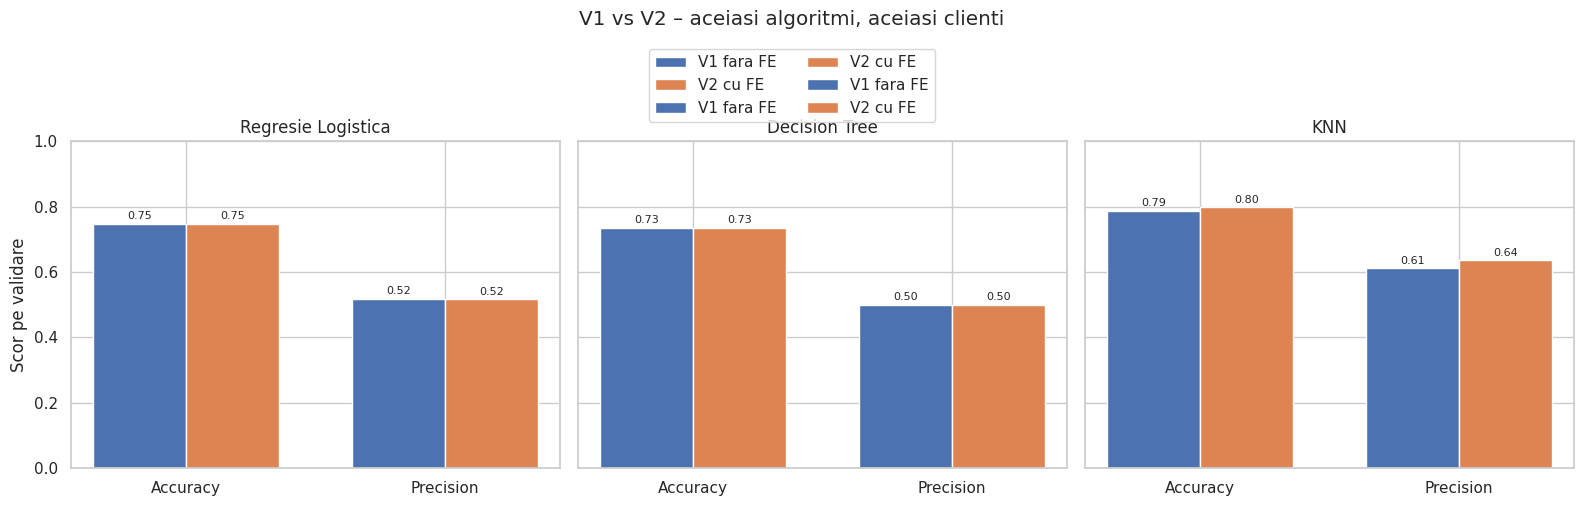

In [16]:
# Selectam caracteristicile numerice si categorice originale din V1
num_v1 = X_train.select_dtypes(include=np.number).columns.tolist()
cat_v1 = X_train.select_dtypes(exclude=np.number).columns.tolist()

# Refacem preprocesarea V1, fara caracteristicile noi
preprocesor_v1 = ColumnTransformer([
    ("num", clone(preprocesare_numerica), num_v1),
    ("cat", clone(preprocesare_categorica), cat_v1)
])

# Folosim hiperparametrii alesi deja in V1
# Nu mai repetam cautarea GridSearchCV
clasificatori_v1 = {
    "Regresie Logistica": LogisticRegression(
        C=0.1, class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=3, min_samples_leaf=5, class_weight="balanced", random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=21, weights="uniform")
}

# Pregatim dictionarul pentru modele si lista pentru rezultate
modele_v1_reproduse = {}
randuri_v1 = []

# Parcurgem fiecare dintre cei 3 algoritmi
for nume in lista_algoritmi:

    # Combinam preprocesarea V1 cu algoritmul curent
    model = Pipeline([
        ("preprocesare", clone(preprocesor_v1)),
        ("clasificator", clone(clasificatori_v1[nume]))
    ])

    # Antrenam modelul doar pe datele originale din V1
    model.fit(X_train, y_train)

    # Pastram modelul antrenat
    modele_v1_reproduse[nume] = model

    # Evaluam modelul pe aceiasi clienti din validare
    randuri_v1.append({
        "Algoritm": nume,
        "Etapa": "V1 fara FE",
        **evalueaza(model, X_val, y_val)
    })

# Transformam rezultatele V1 intr-un tabel
rezultate_v1 = pd.DataFrame(randuri_v1)

# Selectam doar modelele optimizate din V2
rezultate_v2_tuned = comparatie_v2[
    comparatie_v2["Etapa"] == "Optimizat"
].copy()

# Denumim aceste rezultate V2 cu feature engineering
rezultate_v2_tuned["Etapa"] = "V2 cu FE"

# Unim rezultatele V1 si V2 intr-un singur tabel
comparatie_v1_v2 = pd.concat(
    [rezultate_v1, rezultate_v2_tuned], ignore_index=True
)

# Afisam tabelul cu metricile de evaluare
print("Comparatie V1 vs V2 (FE = feature engineering):")
display(comparatie_v1_v2.round(3))

# Cream 3 grafice, cate unul pentru fiecare algoritm
fig, axe = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)

for ax, nume in zip(axe, lista_algoritmi):

    # Selectam rezultatele algoritmului curent
    t = comparatie_v1_v2[
        comparatie_v1_v2["Algoritm"] == nume
    ].set_index("Etapa")

    # Cele doua metrici reprezentate sunt Accuracy si Precision
    x = np.arange(2)

    # Extragem valorile din V1
    initial = [t.loc["V1 fara FE", m] for m in ["Accuracy", "Precision"]]

    # Extragem valorile din V2
    nou = [t.loc["V2 cu FE", m] for m in ["Accuracy", "Precision"]]

    # Desenam barele V1 si V2 una langa alta
    b1 = ax.bar(x - 0.18, initial, 0.36, label="V1 fara FE")
    b2 = ax.bar(x + 0.18, nou, 0.36, label="V2 cu FE")

    # Adaugam numele metricilor si algoritmului
    ax.set_xticks(x, ["Accuracy", "Precision"])
    ax.set_ylim(0, 1)
    ax.set_title(nume)

    # Afisam scorurile deasupra barelor
    ax.bar_label(b1, fmt="%.2f", padding=2, fontsize=8)
    ax.bar_label(b2, fmt="%.2f", padding=2, fontsize=8)

# Adaugam legenda si titlul general
axe[0].set_ylabel("Scor pe validare")
fig.legend(loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.05))
fig.suptitle("V1 vs V2 – aceiasi algoritmi, aceiasi clienti", y=1.12)

# Aranjam si afisam graficele
plt.tight_layout()
plt.show()

### 13. Verificam separat contributia caracteristicilor noi la KNN

Pentru a vedea daca feature engineering ajuta, comparam cinci variante KNN: fara caracteristici noi, cu fiecare dintre cele trei caracteristici separat si cu toate trei impreuna.
Pastram acelasi algoritm si aceiasi hiperparametri: 21 de vecini si voturi egale. Astfel, principala diferenta dintre variante este informatia oferita modelului.
Calculam metricile pentru fiecare varianta si afisam un tabel si un grafic. Urmarim in special F1-score pentru a observa care caracteristici au contribuit la imbunatatirea predictiilor.

Impactul caracteristicilor noi asupra KNN (aceleasi setari):


,Varianta,Accuracy,Precision,F1
0,Fara FE,0.786,0.611,0.572
1,GrupaVechime,0.793,0.626,0.583
2,NrServiciiExtra,0.789,0.614,0.578
3,ContractLunarFibra,0.791,0.617,0.585
4,Toate trei,0.798,0.635,0.595


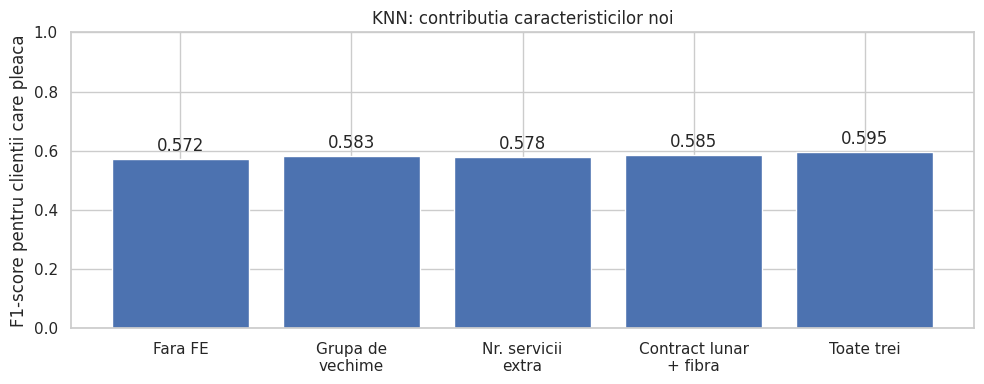

In [18]:
# Comparam KNN fara FE, cu fiecare caracteristica noua si cu toate trei
# Pastram aceiasi hiperparametri pentru o comparatie corecta
variante_fe = {
    "Fara FE": [],
    "GrupaVechime": ["GrupaVechime"],
    "NrServiciiExtra": ["NrServiciiExtra"],
    "ContractLunarFibra": ["ContractLunarFibra"],
    "Toate trei": caracteristici_noi
}

# Lista in care pastram rezultatele fiecarei variante
rezultate_caracteristici = []

# Testam pe rand fiecare combinatie de caracteristici
for varianta, coloane_noi in variante_fe.items():

    # Folosim cele 19 caracteristici originale si cele noi selectate
    coloane_folosite = X_train.columns.tolist() + coloane_noi

    # Selectam aceleasi coloane pentru antrenare si validare
    train_curent = X_train_v2[coloane_folosite]
    val_curent = X_val_v2[coloane_folosite]

    # Identificam coloanele numerice si categorice
    num = train_curent.select_dtypes(include=np.number).columns.tolist()
    cat = train_curent.select_dtypes(exclude=np.number).columns.tolist()

    # Pregatim preprocesarea pentru caracteristicile selectate
    prep = ColumnTransformer([
        ("num", clone(preprocesare_numerica), num),
        ("cat", clone(preprocesare_categorica), cat)
    ])

    # Construim KNN cu 21 de vecini si voturi egale
    knn = Pipeline([
        ("preprocesare", prep),
        ("clasificator", KNeighborsClassifier(n_neighbors=21, weights="uniform"))
    ])

    # Antrenam modelul pe datele de TRAIN
    knn.fit(train_curent, y_train)

    # Realizam predictiile pe setul de VALIDARE
    predictii = knn.predict(val_curent)

    # Calculam metricile pentru varianta curenta
    rezultate_caracteristici.append({
        "Varianta": varianta,
        "Accuracy": accuracy_score(y_val, predictii),
        "Precision": precision_score(y_val, predictii, zero_division=0),
        "F1": f1_score(y_val, predictii, zero_division=0)
    })

# Construim tabelul cu toate rezultatele
impact_fe = pd.DataFrame(rezultate_caracteristici)

print("Impactul caracteristicilor noi asupra KNN (aceleasi setari):")
display(impact_fe.round(3))

# Desenam un grafic pentru compararea F1-score
plt.figure(figsize=(10, 4))

# Fiecare bara reprezinta o varianta de caracteristici
bare = plt.bar(
    ["Fara FE", "Grupa de\nvechime", "Nr. servicii\nextra",
     "Contract lunar\n+ fibra", "Toate trei"],
    impact_fe["F1"]
)

# Afisam scorul deasupra fiecarei bare
plt.bar_label(bare, fmt="%.3f", padding=3)

# Adaugam limitele, etichetele si titlul
plt.ylim(0, 1)
plt.ylabel("F1-score pentru clientii care pleaca")
plt.title("KNN: contributia caracteristicilor noi")

plt.tight_layout()
plt.show()

# Setul de test ramane rezervat pentru etapa finala

### 14. Graficele rapoartelor de clasificare – inainte si dupa tuning
Afisam cate un grafic pentru fiecare algoritm, comparand **Precision, Recall si F1-score** pentru clasa `Yes`. Observam daca tuningul identifica mai multe plecari sau produce mai multe alarme false.

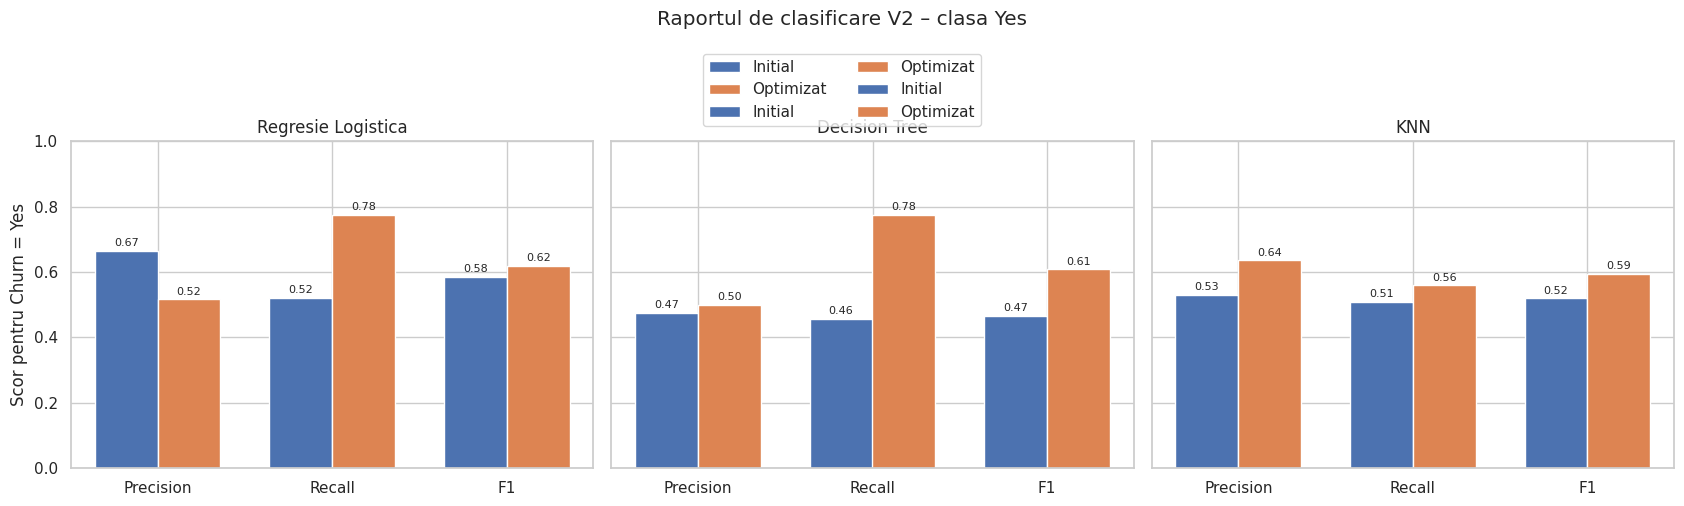

In [ ]:
# 3 grafice: pentru fiecare algoritm comparam modelul initial cu cel optimizat
fig, axe = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
metrici = ["Precision", "Recall", "F1"]
for ax, nume in zip(axe, lista_algoritmi):
    randuri = comparatie_v2[comparatie_v2["Algoritm"] == nume].set_index("Etapa")
    x = np.arange(3)
    vechi = [randuri.loc["Initial", m] for m in metrici]
    nou = [randuri.loc["Optimizat", m] for m in metrici]
    b1 = ax.bar(x - 0.18, vechi, 0.36, label="Initial")
    b2 = ax.bar(x + 0.18, nou, 0.36, label="Optimizat")
    ax.set_xticks(x, metrici)
    ax.set_ylim(0, 1)
    ax.set_title(nume)
    ax.bar_label(b1, fmt="%.2f", padding=2, fontsize=8)
    ax.bar_label(b2, fmt="%.2f", padding=2, fontsize=8)
axe[0].set_ylabel("Scor pentru Churn = Yes")
fig.legend(loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.04))
fig.suptitle("Raportul de clasificare V2 – clasa Yes", y=1.12)
plt.tight_layout()
plt.show()

### 15. Afisam predictii pentru 10 clienti
Pentru **10 clienti din validare**, afisam valoarea reala `Churn` si predictiile celor trei modele optimizate. Astfel vedem concret unde au clasificat corect si unde au gresit.

In [ ]:
# Un exemplu usor de explicat la prezentare: realitate vs predictii
predictii_clienti = pd.DataFrame({
    "Client": df.loc[X_val.index, "customerID"].to_numpy(),
    "Churn real": np.where(y_val.to_numpy() == 1, "Yes", "No")
})
for nume in lista_algoritmi:
    prezis = modele_optimizate[nume].predict(X_val_v2)
    predictii_clienti[nume] = np.where(prezis == 1, "Yes", "No")

display(predictii_clienti.head(10))

,Client,Churn real,Regresie Logistica,Decision Tree,KNN
0,7206-PQBBZ,No,Yes,Yes,Yes
1,9605-WGJVW,No,Yes,Yes,Yes
2,4123-DVHPH,No,Yes,Yes,Yes
3,3196-NVXLZ,No,Yes,Yes,Yes
4,2192-OZITF,No,No,No,No
5,4939-KYYPY,No,No,No,No
6,4718-WXBGI,No,No,No,No
7,3230-IUALN,No,No,No,No
8,1450-GALXR,Yes,Yes,Yes,Yes
9,0613-WUXUM,No,No,No,No


### 16. Matricele de confuzie si analiza greselilor

Afisam matricele de confuzie pentru cele trei modele optimizate, pentru a vedea cate predictii sunt corecte si cate sunt gresite.
Analizam separat doua tipuri de erori: FN reprezinta clientii care au plecat, dar au fost prezisi ca raman, iar FP reprezinta clientii prezisi ca pleaca, desi au ramas.
Alegem modelul cu cel mai bun F1-score din V2 si verificam cum sunt distribuite greselile dupa tipul contractului si vechimea clientilor.

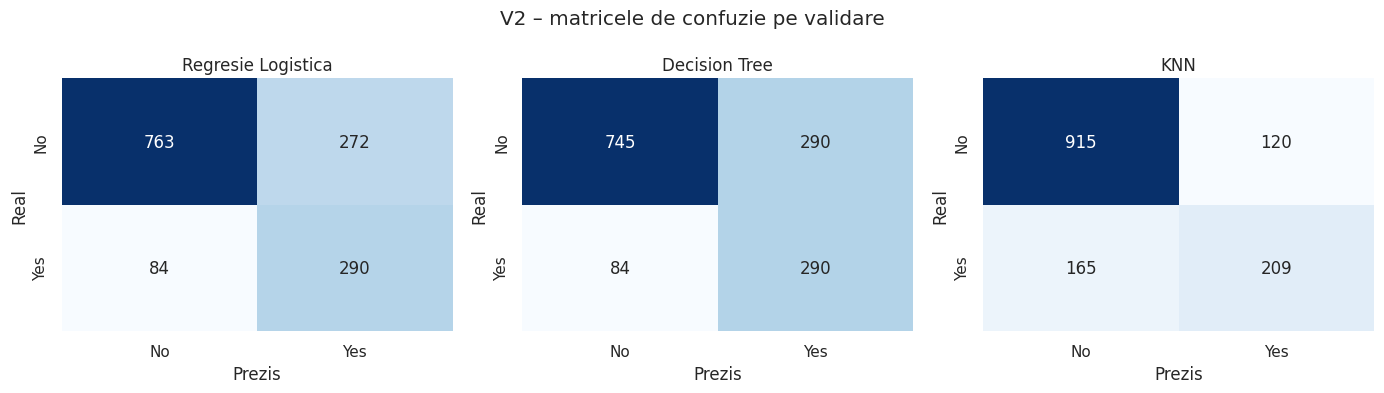

Model ales pentru analiza greselilor: Regresie Logistica
Greseala
Corect                 1053
FP - alarma falsa       272
FN - plecare ratata      84
Name: count, dtype: int64

Greseli pe grupe de Contract :


Greseala,Corect,FN - plecare ratata,FP - alarma falsa
Contract,,,
Month-to-month,479,39,258
One year,262,32,14
Two year,312,13,0



Greseli pe grupe de GrupaVechime :


Greseala,Corect,FN - plecare ratata,FP - alarma falsa
GrupaVechime,,,
0-6,178,10,78
13-24,135,13,41
25-48,264,16,70
49+,372,34,45
7-12,104,11,38


Exemple de clienti care au plecat, dar modelul a prezis No:


,customerID,Contract,tenure,MonthlyCharges,InternetService
4539,4355-HBJHH,Two year,67,79.7,DSL
6290,2530-ENDWQ,Two year,71,93.7,Fiber optic
6772,7931-PXHFC,One year,38,62.3,DSL
2287,5440-FLBQG,Two year,69,108.4,Fiber optic
6746,8976-OQHGT,Month-to-month,4,56.5,DSL


In [19]:
# Cream cate o matrice de confuzie pentru fiecare algoritm optimizat
fig, axe = plt.subplots(1, 3, figsize=(14, 4))

for ax, nume in zip(axe, lista_algoritmi):

    # Obtinem predictiile modelului pe validare
    prezis = modele_optimizate[nume].predict(X_val_v2)

    # Calculam cate predictii sunt corecte si gresite
    matrice = confusion_matrix(y_val, prezis, labels=[0, 1])

    # Afisam matricea sub forma de grafic
    sns.heatmap(
        matrice, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=["No", "Yes"], yticklabels=["No", "Yes"], ax=ax
    )

    ax.set_title(nume)
    ax.set_xlabel("Prezis")
    ax.set_ylabel("Real")

fig.suptitle("V2 – matricele de confuzie pe validare")
plt.tight_layout()
plt.show()

# Alegem modelul optimizat cu cel mai bun F1 pe validare
best_row = comparatie_v2[
    comparatie_v2["Etapa"] == "Optimizat"
].sort_values("F1", ascending=False).iloc[0]

# Obtinem numele modelului si modelul antrenat
nume_ales = best_row["Algoritm"]
model_ales = modele_optimizate[nume_ales]

# Realizam predictiile pentru analiza greselilor
prezis = model_ales.predict(X_val_v2)

# Selectam caracteristicile dupa care vrem sa analizam greselile
analiza = X_val_v2[
    ["Contract", "InternetService", "GrupaVechime"]
].copy()

# Adaugam raspunsurile reale si predictiile
analiza["Real"] = y_val.to_numpy()
analiza["Prezis"] = prezis

# Identificam tipul fiecarei predictii
# FN = client plecat, dar prezis ca ramane
# FP = client ramas, dar prezis ca pleaca
analiza["Greseala"] = np.select(
    [
        (analiza["Real"] == 1) & (analiza["Prezis"] == 0),
        (analiza["Real"] == 0) & (analiza["Prezis"] == 1)
    ],
    ["FN - plecare ratata", "FP - alarma falsa"],
    default="Corect"
)

# Afisam modelul ales si numarul fiecarui tip de rezultat
print("Model ales pentru analiza greselilor:", nume_ales)
print(analiza["Greseala"].value_counts())

# Analizam greselile separat dupa contract si vechime
for grup in ["Contract", "GrupaVechime"]:

    # Numaram greselile din fiecare categorie
    tabel = pd.crosstab(analiza[grup], analiza["Greseala"])

    print("\nGreseli pe grupe de", grup, ":")
    display(tabel)

# Cautam primii 5 clienti care au plecat, dar au fost prezisi No
print("Exemple de clienti care au plecat, dar modelul a prezis No:")

indice_ratat = analiza.index[
    analiza["Greseala"] == "FN - plecare ratata"
][:5]

# Afisam caracteristicile acestor clienti
display(df.loc[
    indice_ratat,
    ["customerID", "Contract", "tenure", "MonthlyCharges", "InternetService"]
])

### 17. Incercam sa reducem greselile prin ajustarea pragului

In mod normal, Regresia Logistica prezice Yes daca probabilitatea estimata de abandon este de cel putin 0,50.
Testam mai multe praguri si alegem valoarea cu cel mai bun F1-score, folosind validare incrucisata doar pe datele de antrenare.
Aplicam pragul ales pe validare si comparam rezultatele cu pragul standard. Urmarim daca scad alarmele false (FP) si daca se modifica numarul plecarilor ratate (FN), deoarece reducerea unui tip de greseala poate duce la cresterea celuilalt.

,Prag,Precision_CV,Recall_CV,F1_CV
0,0.35,0.456,0.901,0.605
1,0.40,0.475,0.874,0.615
2,0.45,0.504,0.841,0.630
3,0.50,0.527,0.808,0.638
4,0.55,0.551,0.761,0.639
5,0.60,0.572,0.708,0.633
6,0.65,0.598,0.656,0.625


Pragul ales din TRAIN: 0.55
Verificare pe VALIDARE – imbunatatirea NU este garantata:


,Varianta,Accuracy,Precision,Recall,F1,FN,FP
0,"Prag standard 0,50",0.747,0.516,0.775,0.620,84,272
1,Prag ales 0.55,0.764,0.540,0.741,0.625,97,236


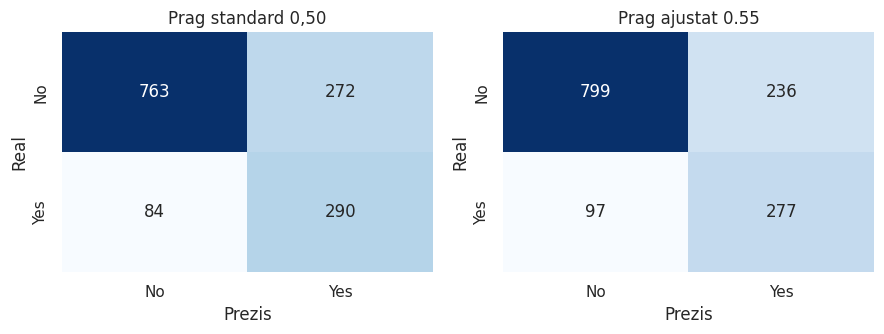

Daca pragul ales este 0,50 sau rezultatele nu cresc, nu fortam o corectie artificiala.


In [20]:
# Predictia standard foloseste pragul de probabilitate 0.50
# Testam daca un alt prag reduce anumite greseli

# Obtinem probabilitatile prin validare incrucisata pe TRAIN
# Fiecare exemplu este prezis de un model care nu l-a antrenat
prob_cv = cross_val_predict(
    model_ales, X_train_v2, y_train,
    cv=cv, method="predict_proba", n_jobs=2
)[:, 1]

# Pregatim lista in care pastram rezultatele pragurilor
randuri_praguri = []

# Verificam mai multe praguri de clasificare
for prag in [0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65]:

    # Prezicem Yes daca probabilitatea depaseste pragul
    prezis_cv = (prob_cv >= prag).astype(int)

    # Calculam metricile pentru fiecare prag
    randuri_praguri.append({
        "Prag": prag,
        "Precision_CV": precision_score(y_train, prezis_cv, zero_division=0),
        "Recall_CV": recall_score(y_train, prezis_cv, zero_division=0),
        "F1_CV": f1_score(y_train, prezis_cv, zero_division=0)
    })

# Transformam rezultatele intr-un tabel
tabel_praguri = pd.DataFrame(randuri_praguri)
display(tabel_praguri.round(3))

# Alegem pragul cu cel mai bun F1 pe TRAIN
# La egalitate, preferam pragul mai apropiat de 0.50
prag_ales = tabel_praguri.assign(
    distanta=(tabel_praguri["Prag"] - 0.50).abs()
).sort_values(
    ["F1_CV", "distanta"],
    ascending=[False, True]
).iloc[0]["Prag"]

# Obtinem probabilitatile modelului pe VALIDARE
prob_val = model_ales.predict_proba(X_val_v2)[:, 1]

# Transformam probabilitatile in clase folosind cele doua praguri
prezis_standard = (prob_val >= 0.50).astype(int)
prezis_corectat = (prob_val >= prag_ales).astype(int)

# Functie pentru calcularea metricilor si a numarului de greseli
def evalueaza_predictii(real, prezis):

    # Extragem cele 4 valori din matricea de confuzie
    tn, fp, fn, tp = confusion_matrix(
        real, prezis, labels=[0, 1]
    ).ravel()

    # Returnam rezultatele evaluarii
    return {
        "Accuracy": accuracy_score(real, prezis),
        "Precision": precision_score(real, prezis, zero_division=0),
        "Recall": recall_score(real, prezis, zero_division=0),
        "F1": f1_score(real, prezis, zero_division=0),
        "FN": int(fn),
        "FP": int(fp)
    }

# Comparam pragul standard cu cel ales
comparatie_prag = pd.DataFrame([
    {
        "Varianta": "Prag standard 0,50",
        **evalueaza_predictii(y_val, prezis_standard)
    },
    {
        "Varianta": f"Prag ales {prag_ales:.2f}",
        **evalueaza_predictii(y_val, prezis_corectat)
    }
])

# Afisam pragul ales si tabelul de comparatie
print("Pragul ales din TRAIN:", prag_ales)
print("Verificare pe VALIDARE – imbunatatirea NU este garantata:")
display(comparatie_prag.round(3))

# Cream doua matrice de confuzie pentru compararea greselilor
fig, axe = plt.subplots(1, 2, figsize=(9, 3.5))

for ax, (titlu, prezis_curent) in zip(axe, [
    ("Prag standard 0,50", prezis_standard),
    (f"Prag ajustat {prag_ales:.2f}", prezis_corectat)
]):

    # Calculam si afisam matricea pentru pragul curent
    sns.heatmap(
        confusion_matrix(y_val, prezis_curent, labels=[0, 1]),
        annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=["No", "Yes"], yticklabels=["No", "Yes"], ax=ax
    )

    ax.set_title(titlu)
    ax.set_xlabel("Prezis")
    ax.set_ylabel("Real")

plt.tight_layout()
plt.show()

# Verificam rezultatele fara sa presupunem ca noul prag este mai bun
print("Daca pragul ales este 0,50 sau rezultatele nu cresc, nu fortam o corectie artificiala.")

### 18. Incercam o corectie suplimentara prin caracteristici noi
Din analiza greselilor am observat ca unele plecari ratate apar la clientii cu vechime mare. Adaugam doua combinatii de caracteristici si reantrenam Regresia Logistica, apoi comparam FN, FP si F1 cu modelul V2 initial. Alegem hiperparametrii numai pe train, iar rezultatele pe validare sunt un experiment, nu o garantie de imbunatatire.

F1 mediu pe TRAIN (3-fold CV):
V2 initial: 0.638
V2 cu indicii: 0.637
Hiperparametrii pentru noul model: {'clasificator__C': 1.0, 'clasificator__class_weight': 'balanced'}
Comparatie pe VALIDARE (FN = plecari ratate; FP = alarme false):


,Varianta,Accuracy,Precision,Recall,F1,FN,FP
0,V2 initial,0.747,0.516,0.775,0.620,84,272
1,V2 cu 2 indicii,0.754,0.525,0.773,0.625,85,262


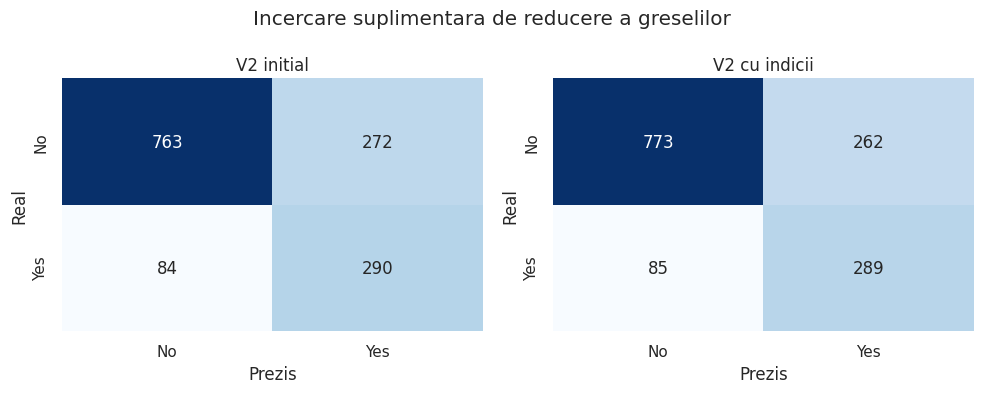

Noul model NU are F1 mai mare pe TRAIN: pastram varianta initiala ca referinta.
Nu folosim setul de TEST. Evaluarea finala va decide ce model generalizeaza mai bine.


In [21]:
# Cream doua caracteristici noi, inspirate de analiza greselilor
# Nu modificam manual raspunsurile reale ale clientilor
def adauga_indicii_pentru_erori(date):

    # Pastram si cele 3 caracteristici create anterior in V2
    date_noi = adauga_caracteristici(date)

    # Indicator pentru clienti vechi care au contract lunar
    date_noi["VechiCuContractLunar"] = (
        (date_noi["tenure"] >= 49) &
        (date_noi["Contract"] == "Month-to-month")
    ).astype(int)

    # Indicator pentru clienti cu contract lunar si internet,
    # dar fara securitate online si suport tehnic
    date_noi["LunarFaraSecuritateSuport"] = (
        (date_noi["Contract"] == "Month-to-month") &
        (date_noi["InternetService"] != "No") &
        (date_noi["OnlineSecurity"] != "Yes") &
        (date_noi["TechSupport"] != "Yes")
    ).astype(int)

    return date_noi

# Aplicam aceleasi reguli pe TRAIN si VALIDARE
X_train_corectie = adauga_indicii_pentru_erori(X_train)
X_val_corectie = adauga_indicii_pentru_erori(X_val)

# Pastram numele celor doua caracteristici experimentale
caracteristici_corectie = [
    "VechiCuContractLunar", "LunarFaraSecuritateSuport"
]

# Identificam coloanele numerice si categorice ale noului set
num_corectie = X_train_corectie.select_dtypes(include=np.number).columns.tolist()
cat_corectie = X_train_corectie.select_dtypes(exclude=np.number).columns.tolist()

# Pregatim preprocesarea pentru toate caracteristicile
preprocesor_corectie = ColumnTransformer([
    ("num", clone(preprocesare_numerica), num_corectie),
    ("cat", clone(preprocesare_categorica), cat_corectie)
])

# Construim o noua Regresie Logistica
model_lr_corectie = Pipeline([
    ("preprocesare", preprocesor_corectie),
    ("clasificator", LogisticRegression(
        max_iter=2000, random_state=RANDOM_STATE
    ))
])

# Optimizam din nou hiperparametrii folosind GridSearchCV
cautare_lr_corectie = GridSearchCV(
    model_lr_corectie, parametri_lr,
    scoring="f1", cv=cv, n_jobs=2
)

# Antrenam si cautam configuratia cea mai buna doar pe TRAIN
cautare_lr_corectie.fit(X_train_corectie, y_train)

# Selectam modelul optimizat cu noile caracteristici
model_corectat = cautare_lr_corectie.best_estimator_

# Evaluam modelul V2 initial si noul model pe aceeasi validare
comparatie_corectie = pd.DataFrame([
    {
        "Varianta": "V2 initial",
        **evalueaza(
            modele_optimizate["Regresie Logistica"],
            X_val_v2, y_val
        )
    },
    {
        "Varianta": "V2 cu 2 indicii",
        **evalueaza(
            model_corectat,
            X_val_corectie, y_val
        )
    }
])

# Comparam F1 obtinut prin validare incrucisata pe TRAIN
print("F1 mediu pe TRAIN (3-fold CV):")
print("V2 initial:", round(cautare_lr.best_score_, 3))
print("V2 cu indicii:", round(cautare_lr_corectie.best_score_, 3))

# Afisam hiperparametrii alesi pentru noul model
print("Hiperparametrii pentru noul model:", cautare_lr_corectie.best_params_)

# Afisam metricile si numarul de greseli pe VALIDARE
print("Comparatie pe VALIDARE (FN = plecari ratate; FP = alarme false):")
display(comparatie_corectie.round(3))

# Cream doua matrice de confuzie pentru compararea modelelor
fig, axe = plt.subplots(1, 2, figsize=(10, 4))

for ax, titlu, model, date in [
    (axe[0], "V2 initial", modele_optimizate["Regresie Logistica"], X_val_v2),
    (axe[1], "V2 cu indicii", model_corectat, X_val_corectie)
]:

    # Calculam matricea pentru fiecare model
    matrice = confusion_matrix(
        y_val, model.predict(date), labels=[0, 1]
    )

    # Afisam numarul predictiilor corecte si gresite
    sns.heatmap(
        matrice, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=["No", "Yes"], yticklabels=["No", "Yes"], ax=ax
    )

    ax.set_title(titlu)
    ax.set_xlabel("Prezis")
    ax.set_ylabel("Real")

plt.suptitle("Incercare suplimentara de reducere a greselilor")
plt.tight_layout()
plt.show()

# Verificam daca noul model are F1 mai bun pe TRAIN
# Nu ne bazam doar pe o crestere mica observata pe validare
if cautare_lr_corectie.best_score_ > cautare_lr.best_score_:
    print("Noul model are F1 mai mare in validarea incrucisata pe TRAIN.")
else:
    print("Noul model NU are F1 mai mare pe TRAIN: pastram varianta initiala ca referinta.")

# Setul de test ramane nefolosit pana la etapa finala
print("Nu folosim setul de TEST. Evaluarea finala va decide ce model generalizeaza mai bine.")

### 19. Salvam rezultatele si modelele V2 pentru etapa finala
Salvam rezultatele si comparatiile in **CSV**, iar modelele optimizate in fisiere **joblib**. Le vom folosi la documentatie si la evaluarea finala; **setul de test nu este folosit aici**.

In [ ]:
# Salvam datele necesare pentru documentatia V2 si compararea la final
comparatie_v2.to_csv("rezultate_V2.csv", index=False)
comparatie_v1_v2.to_csv("comparatie_V1_V2.csv", index=False)
pd.DataFrame(rezultate_cv).to_csv("hiperparametri_V2.csv", index=False)
analiza.to_csv("analiza_greselilor_V2.csv", index=False)
tabel_praguri.to_csv("praguri_V2.csv", index=False)

# Salvam modelele cu preprocesarea inclusa; vor accepta caracteristicile V2
for nume, fisier in [
    ("Regresie Logistica", "model_V2_regresie_logistica.joblib"),
    ("Decision Tree", "model_V2_decision_tree.joblib"),
    ("KNN", "model_V2_knn.joblib")
]:
    joblib.dump(modele_optimizate[nume], fisier)

# Salvam si modelul ales impreuna cu numele si pragul selectat
joblib.dump({"model": model_ales, "algoritm": nume_ales,
             "prag": float(prag_ales), "caracteristici_noi": caracteristici_noi},
            "model_V2_selectat_cu_prag.joblib")

print("Fisierele V2 au fost salvate in sesiunea Google Colab.")
print("Descarca-le pentru a le pastra si folosi la etapa finala.")
print("Setul de test nu a fost folosit nici la V1, nici la V2.")

# Salvam separat experimentul suplimentar, fara sa inlocuim automat modelul V2.
comparatie_corectie.to_csv("comparatie_corectie_greseli_V2.csv", index=False)
joblib.dump({"model": model_corectat,
             "caracteristici_noi": caracteristici_noi + caracteristici_corectie},
            "model_V2_regresie_logistica_cu_indicii.joblib")
print("Am salvat si experimentul suplimentar de corectare a greselilor.")


Fisierele V2 au fost salvate in sesiunea Google Colab.
Descarca-le pentru a le pastra si folosi la etapa finala.
Setul de test nu a fost folosit nici la V1, nici la V2.
Am salvat si experimentul suplimentar de corectare a greselilor.
